Initial state: [7, 6, 4, 3, 1, 2, 5, 0]
Initial cost: 8

Final state: [3, 6, 4, 1, 5, 0, 2, 7]
Final cost: 0
Iterations: 277
Solution found successfully!


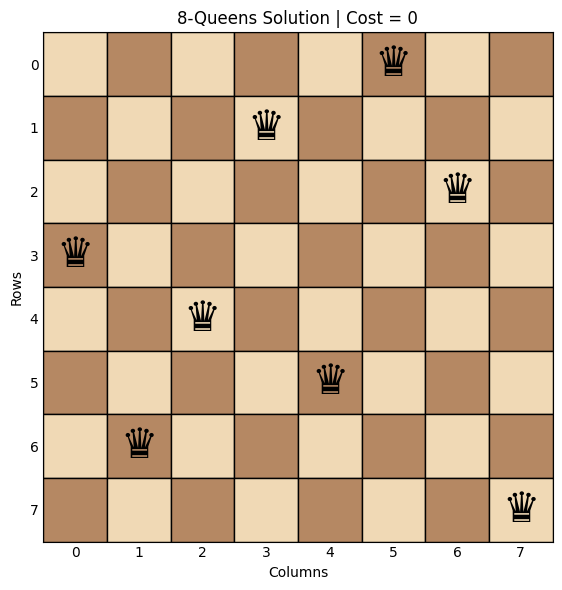

In [1]:

import random
import math
import matplotlib.pyplot as plt

N = 8

# Count pairs of queens attacking each other
def calculate_cost(state):
    conflicts = 0

    for i in range(N):
        for j in range(i + 1, N):
            if state[i] == state[j]:
                conflicts += 1
            elif abs(state[i] - state[j]) == abs(i - j):
                conflicts += 1

    return conflicts


# Generate a random neighbour by swapping two queens
def random_neighbour(state):
    neighbour = state.copy()

    i, j = random.sample(range(N), 2)
    neighbour[i], neighbour[j] = neighbour[j], neighbour[i]

    return neighbour


# Display the chessboard
def display_board(state, title):
    fig, ax = plt.subplots(figsize=(6, 6))

    for row in range(N):
        for col in range(N):
            color = "#F0D9B5" if (row + col) % 2 == 0 else "#B58863"

            ax.add_patch(plt.Rectangle(
                (col, N - 1 - row), 1, 1,
                facecolor=color, edgecolor="black"
            ))

    for col, row in enumerate(state):
        ax.text(
            col + 0.5, N - 1 - row + 0.5, "\u265B",
            fontsize=30, ha="center", va="center",
            color="black"
        )

    ax.set_xlim(0, N)
    ax.set_ylim(0, N)
    ax.set_xticks([i + 0.5 for i in range(N)])
    ax.set_xticklabels(range(N))
    ax.set_yticks([i + 0.5 for i in range(N)])
    ax.set_yticklabels(range(N - 1, -1, -1))
    ax.set_xlabel("Columns")
    ax.set_ylabel("Rows")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.tick_params(length=0)

    plt.tight_layout()
    plt.show()


# Simulated Annealing algorithm
def simulated_annealing():
    current = random.sample(range(N), N)

    temperature = 10.0
    cooling_rate = 0.995
    min_temperature = 0.001
    iteration = 0

    print("Initial state:", current)
    print("Initial cost:", calculate_cost(current))

    while temperature > min_temperature:
        current_cost = calculate_cost(current)

        if current_cost == 0:
            break

        neighbour = random_neighbour(current)
        neighbour_cost = calculate_cost(neighbour)

        delta_E = current_cost - neighbour_cost

        # Accept better states; sometimes accept worse states
        if delta_E > 0:
            current = neighbour
        else:
            probability = math.exp(delta_E / temperature)

            if random.random() < probability:
                current = neighbour

        temperature *= cooling_rate
        iteration += 1

        if iteration % 1000 == 0:
            print(
                f"Iteration: {iteration}, "
                f"Cost: {calculate_cost(current)}, "
                f"Temperature: {temperature:.4f}"
            )

    final_cost = calculate_cost(current)

    print("\nFinal state:", current)
    print("Final cost:", final_cost)
    print("Iterations:", iteration)

    if final_cost == 0:
        print("Solution found successfully!")
    else:
        print("No solution found in this run. Try again.")

    display_board(
        current,
        f"8-Queens Solution | Cost = {final_cost}"
    )

    return current


solution = simulated_annealing()
